In [1]:
import numpy as np
import pandas as pd
import gc
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import resample
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.decomposition import PCA
import datetime
from datetime import timedelta
import random
from imblearn.over_sampling import RandomOverSampler
from numba import njit
import numba as nb
from scipy.stats import zscore
import json
from scipy.stats import spearmanr
import websocket
import warnings
warnings.filterwarnings('ignore')
import random as python_random
import statsmodels.api as sm
import joblib
import sys
import time
import traceback
import torch
import torch.nn as nn
import torch.nn.functional as F 
import os

#import talib as ta

np.random.seed(150)
python_random.seed(150)
import itertools
import copy

In [2]:
gc.collect()


20

In [3]:
#Download ETH data from ex
data2 = pd.read_csv(r'ETH_minute_data.csv')



data2 = data2.rename(columns={'open': 'Open', 'high': 'High', 'low': 'Low', 'close': 'Close','volume': 'Volume'})

data11 = pd.read_csv(r'ETH_2025.csv')
data2 = pd.concat([data2, data11])
data22 = pd.read_csv(r'ETH_2026_up.csv')
data2 = pd.concat([data2, data22])
data2['datetime'] =  pd.to_datetime(data2['datetime'], format='mixed')
data2 = data2.drop(columns=['Unnamed: 0']) 
data2 = data2.drop(columns=['last_update']) 
data2 = data2.drop(columns=['timestamp']) 
data2 = data2.drop(columns=['vwap']) 


#data = pd.merge(data1, data2, on='datetime', how='inner')
data = data2.copy()
hold_pos = 20

data['Avg'] = (data['Open']+data['Low']+data['High']+data['Close'])/4
data = data[['Open', 'High','Low','Close','Volume','datetime','Avg']]

data = data.dropna()
data = data.reset_index(drop = True)
data = data[['Open', 'High','Low','Close','Volume','datetime','Avg']]
data['Log'] = np.log(data['Avg'])

del data2
del data11

data

,Open,High,Low,Close,Volume,datetime,Avg,Log
0,1196.099976,1196.099976,1195.770020,1196.030029,1478.893002,2023-01-01 00:00:00,1196.000000,7.086738
1,1196.020020,1196.270020,1196.020020,1196.030029,737.356000,2023-01-01 00:01:00,1196.085022,7.086809
2,1196.020020,1196.079956,1195.739990,1195.750000,865.134001,2023-01-01 00:02:00,1195.897491,7.086652
3,1195.739990,1195.819946,1195.660034,1195.800049,670.741003,2023-01-01 00:03:00,1195.755005,7.086533
4,1195.790039,1196.300049,1195.420044,1196.290039,1802.253996,2023-01-01 00:04:00,1195.950043,7.086696
...,...,...,...,...,...,...,...,...
1928109,2465.760000,2465.770000,2465.040000,2465.400000,525.214000,2026-08-31 23:55:00,2465.492500,7.810147
1928110,2465.400000,2465.400000,2464.710000,2465.330000,529.030000,2026-08-31 23:56:00,2465.210000,7.810032
1928111,2465.340000,2466.500000,2465.340000,2466.010000,329.737000,2026-08-31 23:57:00,2465.797500,7.810271
1928112,2466.010000,2466.010000,2466.000000,2466.010000,150.804000,2026-08-31 23:58:00,2466.007500,7.810356


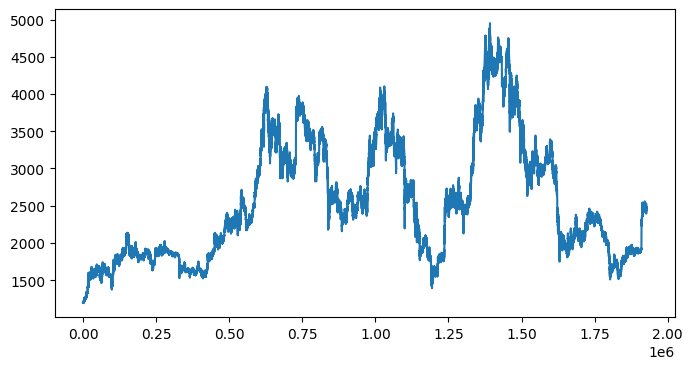

In [4]:
plt.figure(figsize=(8,4))
plt.plot(data['Avg'])

In [5]:
#data['Log'] = np.log(data['Avg'])
#@njit
def run_rolling_nis_dynamic_numba(log_prices, periods, q_lookback, Q_scale=0.1, R_scale=1.0):
    n = len(log_prices)
    sum_nis_output = np.empty(n, dtype=np.float64)
    sum_nis_output[:] = np.nan
    n2 = periods - 1

    # O loop começa garantindo que temos histórico suficiente para o q_lookback e para a janela de teste
    start_idx = max(n2, q_lookback)
    

    # Loop Externo: Desliza a janela de teste ao longo do tempo
    for i in range(start_idx, n):
        window_start = i - n2
        
        # 1. CÁLCULO DINÂMICO: Extrai o histórico estritamente anterior à janela atual
        # Ex: Se q_lookback=120, olha os 120 retornos passados para calibrar o momento atual
        hist_start = window_start - q_lookback
        if hist_start < 0:
            hist_start = 0
            
        hist_prices = log_prices[hist_start : window_start + 1]
        
        # Calcula retornos e variância dinamicamente para esta barra específica
        if len(hist_prices) > 1:
            hist_returns = hist_prices[1:] - hist_prices[:-1]
            base_variance = np.var(hist_returns)
        else:
            base_variance = 1e-8

        # Se o mercado congelar/平, evita divisão por zero
        if base_variance <= 0.0: 
            base_variance = 1e-8

        # 2. ATUALIZAÇÃO DINÂMICA DE Q E R
        global_q = base_variance * Q_scale
        global_r = base_variance * R_scale

        # Inicialização do Filtro para a janela atual com os parâmetros novos
        state_estimate = log_prices[window_start]
        P = global_r 
        window_sum_nis = 0.0

        # Loop Interno: Roda o Filtro de Kalman local com o Q e R atualizados
        for j in range(1, periods):
            price_t = log_prices[window_start + j]

            # Predição
            pred_state = state_estimate
            pred_P = P + global_q

            # Atualização
            innovation = price_t - pred_state
            S_t = pred_P + global_r

            # Acúmulo do NIS
            nis_t = (innovation ** 2) / S_t
            window_sum_nis += nis_t

            # Atualização dos Estados
            K_t = pred_P / S_t
            state_estimate = pred_state + K_t * innovation
            P = (1.0 - K_t) * pred_P

        sum_nis_output[i] = window_sum_nis

    return sum_nis_output

In [6]:
def scan_dataframe_fast_dynamic(df, periods=90, q_lookback=180):
    log_prices_arr = df['Log'].to_numpy()
    

    # Executa a função dinâmica (Q e R mudam a cada linha do dataframe)
    sum_nis_array = run_rolling_nis_dynamic_numba(
        log_prices_arr, periods, q_lookback, Q_scale=0.01, R_scale=10.0
    )

    # Wilson-Hilferty para Chi-Squared 95%
    df_degrees = periods - 1
    z_90 = 1.2815515655446004
    z_95 = 1.6448536269514722
    z_99 = 2.326
    critical_value = df_degrees * (1.0 - 2.0 / (9.0 * df_degrees) + z_95 * np.sqrt(2.0 / (9.0 * df_degrees))) ** 3

    df['sum_nis'] = sum_nis_array
    df['is_stationary'] = sum_nis_array <= critical_value
    df['market_regime'] = np.where(
        df['sum_nis'].isna(), 'WARMUP',
        np.where(df['is_stationary'], 'STATIONARY', 'NON-STATIONARY')
    )
    
    return df

In [7]:
data = scan_dataframe_fast_dynamic(data, periods=10, q_lookback=60)
stationary = len(data[data['market_regime']=='STATIONARY'])
non_stationary = len(data[data['market_regime']=='NON-STATIONARY'])       
print(stationary/(stationary+non_stationary))

0.9740391088631335


In [8]:
# Function to create factors and define targets
def dat(data, hold_pos, target):

    df = pd.DataFrame(data)

    
    ###############AROON ##################
    
    @njit
    def fast_aroon_osc(high, low, window):
        n = len(high)
        out = np.full(n, np.nan)

        for i in range(window - 1, n):
            # Busca o máximo e mínimo na janela manualmente (muito rápido no Numba)
            max_idx = 0
            min_idx = 0
            max_val = high[i - window + 1]
            min_val = low[i - window + 1]

            for j in range(1, window):
                curr_h = high[i - window + 1 + j]
                curr_l = low[i - window + 1 + j]

                if curr_h >= max_val:
                    max_val = curr_h
                    max_idx = j
                if curr_l <= min_val:
                    min_val = curr_l
                    min_idx = j

            up = ((max_idx + 1) / window) * 100
            down = ((min_idx + 1) / window) * 100
            out[i] = up - down
            
        return out

    # No seu loop:
    high_arr = df['High'].values
    low_arr = df['Low'].values

    for i in range(15, 256, 10):
        df[f'AAR_{i}'] = fast_aroon_osc(high_arr, low_arr, i)
        
        
        
    ######################### Volume profile####################################
        
    @njit
    def fast_poc_expanding_numba(close, volume, max_window=300, min_periods=70, bins=20):
        n = len(close)
        out = np.full(n, np.nan)

        # Começamos a calcular apenas após atingir o min_periods (70)
        for i in range(min_periods - 1, n):
            # Lógica da Janela Expansiva:
            # Se i < 300, a janela é [0 : i+1] (tamanho i+1)
            # Se i >= 300, a janela é [i-299 : i+1] (tamanho fixo 300)
            start = max(0, i - max_window + 1)

            w_close = close[start : i + 1]
            w_vol = volume[start : i + 1]

            p_min = np.min(w_close)
            p_max = np.max(w_close)

            if p_min >= p_max:
                out[i] = 0.0
                continue

            # Histograma manual (Otimizado para Numba)
            hist = np.zeros(bins)
            bin_width = (p_max - p_min) / bins

            for j in range(len(w_close)):
                # Calcula o bin correspondente
                val = w_close[j]
                idx = int((val - p_min) / bin_width)
                if idx >= bins: 
                    idx = bins - 1 # Garante que o valor máximo entre no último bin
                hist[idx] += w_vol[j]

            # Encontra o bin com maior volume (Point of Control)
            max_bin_idx = np.argmax(hist)
            poc = p_min + (max_bin_idx + 0.5) * bin_width

            # p_last / poc - 1 (Sinal de desvio do preço médio de volume)
            out[i] = close[i] / poc - 1

        return out

    # Chamada corrigida
    df['Vpro_20'] = fast_poc_expanding_numba(
        df['Close'].values, 
        df['Volume'].values, 
        max_window=300, 
        min_periods=70,
        bins=20
    )
    
   
    
    
    
     ############## VWAP #################
   
    @njit
    def fast_vwap_zscore(close, high, low, volume, max_window=300, min_periods=30):
        n = len(close)
        vwap_z = np.full(n, np.nan)

        # Preço Típico ponderado por Volume: (H+L+C)/3 * Vol
        tp_vol = ((close + high + low) / 3.0) * volume

        for i in range(min_periods - 1, n):
            # Define o início da janela (expansiva até max_window)
            start = max(0, i - max_window + 1)

            # Somas para o VWAP
            sum_tp_vol = np.sum(tp_vol[start : i + 1])
            sum_vol = np.sum(volume[start : i + 1])

            if sum_vol == 0:
                vwap_z[i] = 0.0
                continue

            current_vwap = sum_tp_vol / sum_vol

            # Para o Z-Score (df['Close'] - vwap) / std(vwap)
            # Note: Seu código original calcula o desvio padrão do HISTÓRICO do VWAP
            if i >= start + min_periods:
                # Precisamos calcular o desvio padrão dos valores de VWAP na janela
                # Para performance, vamos extrair o histórico de VWAPs parciais
                window_vwaps = np.zeros(i - start + 1)
                temp_tp_vol = 0.0
                temp_vol = 0.0

                # Este sub-loop calcula o histórico de VWAPs para o desvio padrão
                for k in range(start, i + 1):
                    temp_tp_vol = np.sum(tp_vol[start : k + 1])
                    temp_vol = np.sum(volume[start : k + 1])
                    window_vwaps[k - start] = temp_tp_vol / temp_vol if temp_vol != 0 else current_vwap

                std_vwap = np.std(window_vwaps)

                if std_vwap != 0:
                    vwap_z[i] = (close[i] - current_vwap) / std_vwap
                else:
                    vwap_z[i] = 0.0

        return vwap_z
    
      # Chamada no DataFrame
   
    df['VWAP_300'] = fast_vwap_zscore(
        df['Close'].values, df['High'].values, 
        df['Low'].values, df['Volume'].values, 300
    )
    
    
    ###### Weighted MACD short term ######
        
    @nb.njit(parallel=True, cache=True)
    def calculate_vwap_numba(Close, Low, High, Volume, window, min_periods):
        """Calculates a moving 300-period VWAP using pre-allocated native arrays."""
        n = len(Close)
        vwap_base = np.empty(n)
        vwap_base[:] = np.nan

        # Pre-calculate Typical Price * Volume
        t_pr_vol = ((Close + Low + High) / 3.0) * Volume

        # Parallel window processing
        for i in nb.prange(n):
            if i < min_periods - 1:
                continue
            start = max(0, i - window + 1)

            sum_t_pr = 0.0
            sum_vol = 0.0
            for j in range(start, i + 1):
                sum_t_pr += t_pr_vol[j]
                sum_vol += Volume[j]

            if sum_vol != 0.0:
                vwap_base[i] = sum_t_pr / sum_vol

        return Close / vwap_base - 1.0

    @nb.njit(cache=True)
    def ewm_numba(arr, span):
        """Calculates Exponential Moving Average matching Pandas 'adjust=False'."""
        n = len(arr)
        out = np.empty(n, dtype=np.float64) # 🟢 FIXED: Allocates a clean, isolated array in memory
        if n == 0:
            return out

        alpha = 2.0 / (span + 1.0)

        # Safely prime the first valid element
        if n > 0:
            out[0] = arr[0]

        for i in range(1, n):
            if np.isnan(arr[i]):
                out[i] = out[i-1]
            elif np.isnan(out[i-1]):
                out[i] = arr[i]
            else:
                out[i] = arr[i] * alpha + out[i-1] * (1.0 - alpha)
        return out

    @nb.njit(cache=True)
    def rolling_mean_numba(arr, window):
        """Calculates standard Simple Moving Average (SMA)."""
        n = len(arr)
        out = np.empty(n)
        out[:] = np.nan

        if n < window:
            return out

        current_sum = 0.0
        for i in range(window):
            current_sum += arr[i]
        out[window - 1] = current_sum / window

        for i in range(window, n):
            current_sum += arr[i] - arr[i - window]
            out[i] = current_sum / window
        return out

    @nb.njit(parallel=True, cache=True)
    def process_signals_numba(Close, vwap2, n1, n2, n3):
        """Processes MACD EWM/Rolling layers and handles vectorized signal logic."""
        n = len(Close)

        # --- 1. EXPONENTIAL MACD LAYER (EWM) ---
        ma_fast_ewm = ewm_numba(Close, n1)
        ma_slow_ewm = ewm_numba(Close, n2)
        ma_ewm = ma_fast_ewm - ma_slow_ewm
        sig_ewm = ewm_numba(ma_ewm, n3)
        macds_ewm = ma_ewm - sig_ewm
        macd_out = np.zeros(n)

        # --- 2. ROLLING MACD LAYER (SMA) ---
        ma_fast_roll = rolling_mean_numba(Close, n1)
        ma_slow_roll = rolling_mean_numba(Close, n2)
        ma_roll = ma_fast_roll - ma_slow_roll
        sig_roll = ewm_numba(ma_roll, n3)
        macds_roll = ma_roll - sig_roll
        macdn_out = np.zeros(n)

        # --- 3. SIGNAL TRIGGERING AND HISTOGRAM LOGIC ---
        for t in nb.prange(1, n):
            # EWM Signals (Utilizes trend filter via vwap2)
            cross_up_ewm = (ma_ewm[t] > sig_ewm[t]) and (ma_ewm[t-1] <= sig_ewm[t-1])
            cross_down_ewm = (ma_ewm[t] < sig_ewm[t]) and (ma_ewm[t-1] >= sig_ewm[t-1])

            cond_long_ewm = (ma_ewm[t] < 0.0) and cross_up_ewm and (vwap2[t] > 0.0)
            cond_short_ewm = (ma_ewm[t] > 0.0) and cross_down_ewm and (vwap2[t] < 0.0)

            if cond_long_ewm or cond_short_ewm:
                macd_out[t] = macds_ewm[t]

            # Rolling Signals
            if np.isnan(ma_roll[t]) or np.isnan(sig_roll[t]) or np.isnan(ma_roll[t-1]) or np.isnan(sig_roll[t-1]):
                continue

            cross_up_roll = (ma_roll[t] > sig_roll[t]) and (ma_roll[t-1] <= sig_roll[t-1])
            cross_down_roll = (ma_roll[t] < sig_roll[t]) and (ma_roll[t-1] >= sig_roll[t-1])

            cond_long_roll = (ma_roll[t] < 0.0) and cross_up_roll
            cond_short_roll = (ma_roll[t] > 0.0) and cross_down_roll

            if cond_long_roll or cond_short_roll:
                macdn_out[t] = macds_roll[t]

        return macd_out, ma_ewm, macds_ewm, macdn_out

    # --- 2. MAIN INTEGRATION WRAPPER FOR PANDAS DATAFRAMES ---

    def execute_strategy_numba(df):
        """Extracts NumPy arrays from DataFrame, triggers Numba, and commits back."""
        Close = np.ascontiguousarray(df['Close'].to_numpy(dtype=np.float64))
        Low = np.ascontiguousarray(df['Low'].to_numpy(dtype=np.float64))
        High = np.ascontiguousarray(df['High'].to_numpy(dtype=np.float64))
        Volume = np.ascontiguousarray(df['Volume'].to_numpy(dtype=np.float64))

        # Step 1: Pre-calculate 300 VWAP layer outside loop
        df['vwap2'] = calculate_vwap_numba(Close, Low, High, Volume, window=300, min_periods=70)
        vwap2_arr = np.ascontiguousarray(df['vwap2'].to_numpy(dtype=np.float64))

        # Step 2: Unified loop execution
        for i in range(48, 135, 6):
            n1, n2, n3 = i, 2 * i, int(round(i / 1.5)) # 🟢 OPTIMIZED: Forces explicit int signature to ensure clean compilation

            macd_out, ma_ewm, macds_ewm, macdn_out = process_signals_numba(
                Close, vwap2_arr, n1, n2, n3
            )

            df[f'MACD_{i}'] = macd_out
            df[f'MA_{i}'] = ma_ewm
            df[f'MACDS_{i}'] = macds_ewm
            df[f'MACDN_{i}'] = macdn_out
            
            df[f'MACD_{i}_d'] = df[f'MACD_{i}'].diff(100)
            df[f'MA_{i}_d'] = df[f'MA_{i}'].diff(100)
            df[f'MACDS_{i}_d'] = df[f'MACDS_{i}'].diff(100)
            df[f'MACDN_{i}_d'] = df[f'MACDN_{i}'].diff(100)

        return df

    # Execute the strategy using your DataFrame
    df = execute_strategy_numba(df)

    ####### HEIKEN ASHI ################

    @njit # Compilação Just-In-Time para performance máxima
    def _calcular_ha_core_fast(op, hi, lo, cl, vw):
        n = len(op)
        ha_open = np.empty(n)
        ha_close = (op + hi + lo + cl) / 4.0

        # Primeiro candle (Seed)
        ha_open[0] = (op[0] + cl[0]) / 2.0

        # Loop recursivo Heikin-Ashi
        for i in range(1, n):
            ha_open[i] = (ha_open[i-1] + ha_close[i-1]) / 2.0

        ha_high = np.maximum(hi, np.maximum(ha_open, ha_close))
        ha_low = np.minimum(lo, np.minimum(ha_open, ha_close))

        sinal = np.zeros(n)

        # Começa em 1 para evitar que i-1 acesse o índice de trás incorretamente
        for i in range(1, n):
           
            if (ha_close[i] > ha_open[i]) and (ha_open[i]==ha_low[i]):
                sinal[i] = 1.0
            elif (ha_close[i] > ha_open[i]) and (ha_close[i-1] < ha_open[i]):
                sinal[i] = 1.0
            
            elif (ha_close[i] < ha_open[i]) and (ha_open[i]==ha_high[i]):
                sinal[i] = -1.0  
            elif (ha_close[i] < ha_open[i]) and (ha_close[i-1] > ha_open[i]):
                sinal[i] = -1.0
                
                
        return sinal

    @njit
    def _sequence_counter_fast(sinal):
        n = len(sinal)
        ha_count = np.zeros(n)
        current_sum = 0.0

        for i in range(n):
            if sinal[i] == 0.0:
                current_sum = 0.0
            elif i > 0 and sinal[i] != sinal[i-1]:
                current_sum = sinal[i]  # Reinicia a contagem com o novo sinal
            else:
                current_sum += sinal[i]
            ha_count[i] = current_sum
        return ha_count

    def HA(df):
        # Passa apenas os arrays numéricos brutos (.values) para as funções aceleradas
        sinal = _calcular_ha_core_fast(
            df['Open'].values, 
            df['High'].values, 
            df['Low'].values, 
            df['Close'].values, 
            df['vwap2'].values
        )

        df['HA_Sinal'] = sinal
        df['HA_Seq'] = _sequence_counter_fast(sinal)
        return df
    # Dataframe integration
    
    df = HA(df)

    ########CCI

    @njit
    def calcular_cci_fast(typ_price, window):
        n = len(typ_price)
        out = np.full(n, np.nan)

        for i in range(window - 1, n):
            # 1. Seleciona a janela do Preço Típico
            janela = typ_price[i - window + 1 : i + 1]

            # 2. Média Móvel do Preço Típico (TP_MA)
            tp_ma = np.mean(janela)

            # 3. Desvio Médio Absoluto (MAD) 
            # A fórmula correta é a média de abs(Preço Típico - Média do Preço Típico)
            mad = np.mean(np.abs(janela - tp_ma))

            # 4. Cálculo do CCI
            if mad != 0:
                out[i] = (typ_price[i] - tp_ma) / (0.015 * mad)
            else:
                out[i] = 0

        return out

    # Integração no seu Loop
    tp = ((df['High'] + df['Low'] + df['Close']) / 3).values

    for i in range(50, 151, 5):
        df[f'CCI_{i}'] = calcular_cci_fast(tp, i)

    ################### ATR - volatility indicator

    @njit
    def calcular_atr_wilder(high, low, close, window):
        n = len(high)
        tr = np.zeros(n)
        atr = np.zeros(n)

        # 1. Cálculo do True Range (TR)
        for i in range(1, n):
            hl = high[i] - low[i]
            hc = abs(high[i] - close[i-1])
            lc = abs(low[i] - close[i-1])
            tr[i] = max(hl, max(hc, lc))
        tr[0] = high[0] - low[0] # Primeiro valor

        # 2. Cálculo do ATR (Suavização de Wilder)
        # Primeiro ATR é a média simples dos primeiros 'window' TRs
        sum_tr = 0.0
        for i in range(window):
            sum_tr += tr[i]
        atr[window-1] = sum_tr / window

        # Próximos ATRs: (ATR_anterior * (n-1) + TR_atual) / n
        for i in range(window, n):
            atr[i] = (atr[i-1] * (window - 1) + tr[i]) / window

        return atr

    # Extração dos arrays
    h = df['High'].values
    l = df['Low'].values
    c = df['Close'].values

    for i in range(7, 92, 7):
        # Calcula o ATR e já normaliza pelo Close (como no seu código original)
        atr_values = calcular_atr_wilder(h, l, c, i)
        df[f'ATR_{i}'] = atr_values/c
        #df[f'ATR_{i}_Z'] = (df['ATR_7'] - df['ATR_7'].rolling(100).mean()) / df['ATR_7'].rolling(100).std()



   ############### TGT Target
    ### Different targets for different holding periods and models.ewm(span=n1, adjust=False).mean()
    # Se possível, evite o shift negativo se o objetivo for backtest real
    
    
    target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=False).mean()
    target_price2 = df['Avg'].ewm(span=int(hold_pos), adjust=False).mean()

    # 2. Realize a operação usando valores brutos (numpy) para economizar RAM
    df["ret"] = (target_price.values / df['Avg'].values) - 1
    df["ret2"] = (target_price2.values / df['Avg'].shift(hold_pos).values) - 1
    
    target_price1 = df['Avg'].shift(int(-hold_pos))
    target_price22 = df['Avg'].shift(int(-hold_pos*0.9))
    target_price33 = df['Avg'].shift(int(-hold_pos*0.8))
    #target_price4 = df['Avg'].shift(int(-hold_pos*0.7))
    #target_price5 = df['Avg'].shift(int(-hold_pos*0.6))
    #target_price6 = df['Avg'].shift(int(-hold_pos*0.5))

    # 2. Realize a operação usando valores brutos (numpy) para economizar RAM
    df["ret11"] = (target_price1.values / df['Avg'].values) - 1
    df["ret22"] = (target_price22.values / df['Avg'].values) - 1
    df["ret33"] = (target_price33.values / df['Avg'].values) - 1
    #df["ret4"] = (target_price4.values / df['Avg'].values) - 1
    #df["ret5"] = (target_price5.values / df['Avg'].values) - 1
    #df["ret6"] = (target_price6.values / df['Avg'].values) - 1

    # 3. Limpeza manual se necessário
    del target_price
    
    @njit
    def ewm_truncated(x, span=10):
        n = x.shape[0]
        out = np.full(n, np.nan, dtype=np.float64)

        # 1. Criação vetorizada dos pesos
        alpha = 2.0 / (span + 1)
        w = alpha * ((1 - alpha) ** np.arange(span))

        # 2. Normalização dos pesos para somarem 1
        w /= np.sum(w)

        # 3. Convolução matemática (substitui os loops de forma ultra rápida)
        # mode='valid' calcula apenas onde a janela de tamanho 'span' cabe inteira
        out[span-1:] = np.convolve(x, w, mode='valid')

        return out
    
    

    if target==1:
        
        target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=False).mean()
        df['Tgt'] = (target_price.values / df['Avg'].values) - 1
        #df['Tgt'] = (df['Tgt'] + df['ret'])/2
        # Define a historical lookback window (e.g., 500 or 1000 rows)
        #z_lookback = 500  

        # Calculate rolling statistical baselines based ONLY on past data
        #rolling_mean = df['Tgt'].rolling(window=z_lookback, min_periods=30).mean()
        #rolling_std = df['Tgt'].rolling(window=z_lookback, min_periods=30).std()
        #df["Mean"] = rolling_mean
        #df["Std"] = rolling_std

        # Apply the Z-score transformation: (X - Mean) / Std
        # We add a tiny epsilon (1e-8) to prevent zero-division errors if volatility crushes to 0
        #df['Tgt'] = (df['Tgt'] - rolling_mean) / (rolling_std + 1e-8)
        
        #inconcistency
        df['Tgt'] = np.where((df['Tgt'] < 0) & (df['ret11'] > 0) & (df['ret22'] > 0) & (df['ret33'] > 0) , 0, df['Tgt'])
        df['Tgt'] = np.where((df['Tgt'] > 0) & (df['ret11'] < 0) & (df['ret22'] < 0) & (df['ret33'] < 0), 0, df['Tgt'])
        
        df['Trig'] = df['ret2'].abs().rolling(25).mean()         
        #df['Trig'] = df['ret'].abs().rolling(5).mean() 
        #move trig ahead not to use future data
        df['Trig'] = df['Trig'].shift(hold_pos)

    elif target==2:
        target_price = ewm_truncated(df['Avg'].shift(-hold_pos).values.astype(float), span=int(hold_pos))
        #target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=True).mean()
        df['Tgt0'] = (target_price / df['Avg'].values) - 1
        df['Tgt1'] = (df['Tgt0'] + df['ret'])/2
        # Define a historical lookback window (e.g., 500 or 1000 rows)
        z_lookback = 500  

        # Calculate rolling statistical baselines based ONLY on past data
        #rolling_mean = df['Tgt1'].rolling(window=z_lookback, min_periods=30).mean().shift(hold_pos)
        #rolling_std = df['Tgt1'].rolling(window=z_lookback, min_periods=30).std().shift(hold_pos)
        #df["Mean"] = rolling_mean
        #df["Std"] = rolling_std
 
        # Apply the Z-score transformation: (X - Mean) / Std
        # We add a tiny epsilon (1e-8) to prevent zero-division errors if volatility crushes to 0
        #df['Tgt'] = (df['Tgt1'] - rolling_mean) / (rolling_std + 1e-8)
        df['Tgt'] = df['Tgt1']
        #correcting possible discrepancies
        df['Tgt'] = np.where((df['Tgt'] < 0) & (df['ret11'] > 0), 0, df['Tgt'])
        df['Tgt'] = np.where((df['Tgt'] > 0) & (df['ret11'] < 0) , 0, df['Tgt'])
        
        df['Trig'] = df['ret2'].abs().rolling(25).mean()         
        #df['Trig'] = df['ret'].abs().rolling(5).mean() 
        #move trig ahead not to use future data
        df['Trig'] = df['Trig'].shift(hold_pos)

    elif target==3:
        target_price = ewm_truncated(df['Avg'].shift(-hold_pos).values.astype(float), span=int(hold_pos))
        #target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=True).mean()
        df['Tgt0'] = (target_price / df['Avg'].values) - 1
        #df['Tgt1'] = (df['Tgt0'] + df['ret'])/2
        # Define a historical lookback window (e.g., 500 or 1000 rows)
        z_lookback = 500  

        # Calculate rolling statistical baselines based ONLY on past data
        rolling_mean = df['Tgt0'].rolling(window=z_lookback, min_periods=30).mean().shift(hold_pos)
        rolling_std = df['Tgt0'].rolling(window=z_lookback, min_periods=30).std().shift(hold_pos)
        df["Mean"] = rolling_mean
        df["Std"] = rolling_std
 
        # Apply the Z-score transformation: (X - Mean) / Std
        # We add a tiny epsilon (1e-8) to prevent zero-division errors if volatility crushes to 0
        df['Tgt'] = (df['Tgt0'] - rolling_mean) / (rolling_std + 1e-8)
        
        #correcting possible discrepancies
        df['Tgt'] = np.where((df['Tgt'] < 0) & (df['ret'] > 0), 0, df['Tgt'])
        df['Tgt'] = np.where((df['Tgt'] > 0) & (df['ret'] < 0) , 0, df['Tgt'])
        
        df['Trig'] = df['ret2'].abs().rolling(25).mean()         
        #df['Trig'] = df['ret'].abs().rolling(5).mean() 
        #move trig ahead not to use future data
        df['Trig'] = df['Trig'].shift(hold_pos)
        
        
    
    elif target==4:
        #target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=False).mean()
        target_price = df['Avg'].shift(-hold_pos).rolling(int(hold_pos/2)).mean()
        df['Tgt'] = (target_price.values / df['Avg'].values) - 1
        
        target_price1 = df['Avg'].shift(int(-hold_pos))
        target_price2 = df['Avg'].shift(int(-hold_pos*0.9))
        target_price3 = df['Avg'].shift(int(-hold_pos*0.8))
        target_price4 = df['Avg'].shift(int(-hold_pos*0.7))
        #target_price5 = df['Avg'].shift(int(-hold_pos*0.6))
        #target_price6 = df['Avg'].shift(int(-hold_pos*0.5))

        # 2. Realize a operação usando valores brutos (numpy) para economizar RAM
        df["ret1"] = (target_price1.values / df['Avg'].values) - 1
        df["ret2"] = (target_price2.values / df['Avg'].values) - 1
        df["ret3"] = (target_price3.values / df['Avg'].values) - 1
        df["ret4"] = (target_price4.values / df['Avg'].values) - 1
        #df["ret5"] = (target_price5.values / df['Avg'].values) - 1
        #df["ret6"] = (target_price6.values / df['Avg'].values) - 1
        
        #df['Tgt'] =(df['ret1'] + df['ret2'] + df['ret3'] + df['ret4'] + df['ret5'] + df['ret6'])/6
        #df['Tgt'] =(df['Tgt'] + df['ret1'] +  df['ret4'])/3
        #df['Tgt'] = df['ret1']
        
               
               
        # Define a historical lookback window (e.g., 500 or 1000 rows)
        z_lookback = 200  

        # Calculate rolling statistical baselines based ONLY on past data
        rolling_mean = df['Tgt'].rolling(window=z_lookback, min_periods=100).mean().shift(hold_pos)
        rolling_std = df['Tgt'].rolling(window=z_lookback, min_periods=100).std().shift(hold_pos)
        df["Mean"] = rolling_mean
        df["Std"] = rolling_std
 
        # Apply the Z-score transformation: (X - Mean) / Std
        # We add a tiny epsilon (1e-8) to prevent zero-division errors if volatility crushes to 0
        df['Tgt'] = (df['Tgt'] - rolling_mean) / (rolling_std + 1e-8)
        
         #inconcistency
        df['Tgt'] = np.where((df['Tgt'] > 0) & (df['ret1'] > 0) | 
                             (df['Tgt'] < 0) & (df['ret1'] < 0), df['Tgt'], 0)
        
        
        
        
                
        df['Trig'] = df['ret2'].abs().rolling(25).mean()         
        #df['Trig'] = df['ret'].abs().rolling(5).mean() 
        #move trig ahead not to use future data
        df['Trig'] = df['Trig'].shift(hold_pos)

    elif target==5:

        # 1. Lookahead metrics
        df["sup_Low"] = df['Low'].shift(-hold_pos).rolling(hold_pos).min() / df['Close'] - 1
        df["sup_High"] = df['High'].shift(-hold_pos).rolling(hold_pos).max() / df['Close'] - 1
        
        target_price = ewm_truncated(df['Avg'].shift(int(-hold_pos)).values.astype(float), span=int(int(hold_pos)))
        df['Tgt'] = (target_price/df['Close'] - 1) + df["sup_High"] + df["sup_Low"]
        
                
        #df['Tgt'] = np.where((df['Tgt1'] > 0) & (df['ret11'] > 0) | (df['Tgt1'] < 0) & (df['ret11'] < 0), df['Tgt1'], 0)
        
        
        df['Trig'] = df['ret2'].abs().rolling(25).mean() 
        #move trig ahead not to use future data
        df['Trig'] = df['Trig'].shift(hold_pos)
        
        
        
    ###########RSI 15
    df['S1_pct'] = df['Close'].pct_change()

    @njit
    def calcular_rsi_wilder(changes, window):
        n = len(changes)
        rsi = np.full(n, np.nan)

        # Separar ganhos e perdas (Vetorizado no Numba)
        gains = np.where(changes > 0, changes, 0.0)
        losses = np.where(changes < 0, -changes, 0.0)

        # Inicialização (Média simples para o primeiro valor)
        avg_gain = np.mean(gains[:window])
        avg_loss = np.mean(losses[:window])

        if avg_loss == 0:
            rsi[window-1] = 100
        else:
            rs = avg_gain / (avg_loss + 1e-10)
            rsi[window-1] = 100 - (100 / (1 + rs))

        # Suavização de Wilder (Recursiva)
        for i in range(window, n):
            avg_gain = (avg_gain * (window - 1) + gains[i]) / window
            avg_loss = (avg_loss * (window - 1) + losses[i]) / window

            if avg_loss == 0:
                rsi[i] = 100
            else:
                rs = avg_gain / (avg_loss + 1e-10)
                rsi[i] = 100 - (100 / (1 + rs))

        return rsi - 50 # Retorna centralizado no 0 conforme seu código

    # Integração no seu Loop
    # Assumindo que S1_pct é a variação percentual do Close
    changes = df['S1_pct'].values

    for i in range(80, 201, 10):
        df[f'RSI_{i}'] = calcular_rsi_wilder(changes, i)

    ####################################VPIN

    @njit
    def _numba_dynamic_vpin(close, high, low, volume, window_mins=30):
        n = len(close)
        vb_min = np.zeros(n)
        vs_min = np.zeros(n)
        for i in range(n):
            r = high[i] - low[i]
            ratio = (close[i] - low[i]) / r if r > 0 else 0.5
            # clamp pra evitar ratio > 1 por causa de close fora do range
            if ratio > 1.0: ratio = 1.0
            elif ratio < 0.0: ratio = 0.0
            vb_min[i] = volume[i] * ratio
            vs_min[i] = volume[i] * (1.0 - ratio)
        vpin_per_minute = np.full(n, np.nan)
        current_bucket_v = 0.0
        current_vb = 0.0
        current_vs = 0.0
        last_vpin = np.nan
        rolling_vol_sum = np.zeros(n)
        running_sum = 0.0
        for i in range(n):
            running_sum += volume[i]
            if i >= window_mins:
                running_sum -= volume[i - window_mins]
            rolling_vol_sum[i] = running_sum
        for i in range(window_mins, n):
            vol_sum = rolling_vol_sum[i - 1]
            b_size = (vol_sum / window_mins) * 2.0
            if b_size <= 1e-9:
                vpin_per_minute[i] = last_vpin
                continue
            v_rem = volume[i]
            vol = volume[i]
            bar_vb_rate = vb_min[i] / vol if vol > 0 else 0.5
            while v_rem > 1e-9:
                space = b_size - current_bucket_v
                if v_rem >= space:
                    current_vb += space * bar_vb_rate
                    current_vs += space * (1.0 - bar_vb_rate)
                    last_vpin = abs(current_vb - current_vs) / b_size
                    current_bucket_v = 0.0
                    current_vb = 0.0
                    current_vs = 0.0
                    v_rem -= space
                else:
                    current_vb += v_rem * bar_vb_rate
                    current_vs += v_rem * (1.0 - bar_vb_rate)
                    current_bucket_v += v_rem
                    v_rem = 0.0
            vpin_per_minute[i] = last_vpin
        return vpin_per_minute
    @njit
    def _numba_vpin_zscore(vpin, min_period=420, max_period=2100):
        n = len(vpin)
        zscore = np.full(n, np.nan)
        running_sum = 0.0
        running_sq_sum = 0.0
        count = 0
        # buffers para janela rolling O(1)
        # vamos manter sum e sq_sum deslizantes
        window_sum = 0.0
        window_sq_sum = 0.0
        for i in range(n):
            val = vpin[i]
            if np.isnan(val):
                # se pular, não pode atualizar zscore, mas mantém janela
                # precisamos propagar o último cálculo? melhor só continuar
                if count >= min_period and i >= max_period:
                     # se estiver na fase rolling e veio NaN, repete último?
                     zscore[i] = zscore[i-1]
                continue
            running_sum += val
            running_sq_sum += val * val
            count += 1
            if i < max_period:
                # FASE EXPANDING
                if count >= min_period:
                    mean = running_sum / count
                    var = (running_sq_sum / count) - (mean * mean)
                    if var < 1e-10: var = 1e-10
                    zscore[i] = (val - mean) / np.sqrt(var)
                # inicializa janela rolling
                window_sum += val
                window_sq_sum += val * val
            else:
                # FASE ROLLING - O(1)
                # remove o elemento que sai
                old_val = vpin[i - max_period]
                # se old_val era NaN, ele nunca entrou na soma, precisa achar o ultimo valido?
                # simplificação: assumindo vpin sem NaN após warmup
                if not np.isnan(old_val):
                    window_sum += val - old_val
                    window_sq_sum += val*val - old_val*old_val
                else:
                    window_sum += val
                    window_sq_sum += val*val
                mean = window_sum / max_period
                var = (window_sq_sum / max_period) - (mean * mean)
                if var < 1e-10: var = 1e-10
                zscore[i] = (val - mean) / np.sqrt(var)
        return zscore
    
    # Garante cópia para evitar SettingWithCopyWarning
    df = df.copy()
    

    # Executa a função ultra-rápida compilada em Numba
    df['VPIN'] = _numba_dynamic_vpin(df.Close.values, df.High.values, df.Low.values, df.Volume.values)
    df['VPIN_Z'] = _numba_vpin_zscore(df['VPIN'].values)
    
    ######################### ER ####################################
    
    @njit
    def calc_efficiency_ratio_numba_simples(close, period):
        n = close.shape[0]
        out = np.full(n, np.nan, dtype=np.float64)

        # Pré-calcula a variação absoluta barra a barra
        abs_diff = np.abs(close[1:] - close[:-1])

        # O loop só precisa rodar a partir de onde a janela cabe inteira
        for i in range(period, n):
            sinal = abs(close[i] - close[i - period])

            # Slices simples: pega as diferenças do período atual e soma
            ruido = np.sum(abs_diff[i - period : i])

            out[i] = sinal / (ruido + 1e-8)

        return out

    # --- LOOP PARA TESTAR VÁRIOS PERÍODOS ---
    close_prices = df['Close'].values.astype(np.float64)
    periodos_para_testar = [10, 20, 30, 40, 50, 60]

    for p in periodos_para_testar:
        df[f'E_R_{p}'] = calc_efficiency_ratio_numba_simples(close_prices, p)
        #print(f"Feature criada com Numba: Efficiency_Ratio_{p}")

    
    ###############################  Shadow_MA  ##################################################### 
    
    @njit
    def calc_sma_numba(arr, period):
        n = arr.shape[0]
        out = np.full(n, np.nan, dtype=np.float64)

        if n >= period:
            current_sum = 0.0
            for i in range(period):
                current_sum += arr[i]
            out[period - 1] = current_sum / period

            for i in range(period, n):
                current_sum = current_sum - arr[i - period] + arr[i]
                out[i] = current_sum / period
        return out

    # 2. FUNÇÃO PRINCIPAL: Calcula as dinâmicas brutas de candle
    @njit
    def calc_candle_raw_numba(open_arr, high_arr, low_arr, close_arr):
        n = open_arr.shape[0]
        upper_s = np.empty(n, dtype=np.float64)
        lower_s = np.empty(n, dtype=np.float64)
        body_tr = np.empty(n, dtype=np.float64)

        for i in range(n):
            candle_range = (high_arr[i] - low_arr[i]) + 1e-8
            max_body = open_arr[i] if open_arr[i] > close_arr[i] else close_arr[i]
            min_body = close_arr[i] if open_arr[i] > close_arr[i] else open_arr[i]

            upper_s[i] = (high_arr[i] - max_body) / candle_range
            lower_s[i] = (min_body - low_arr[i]) / candle_range
            body_tr[i] = abs(close_arr[i] - open_arr[i]) / candle_range

        return upper_s, lower_s, body_tr

    # --- PREPARAÇÃO DOS DADOS ---
    o = df['Open'].values.astype(np.float64)
    h = df['High'].values.astype(np.float64)
    l = df['Low'].values.astype(np.float64)
    c = df['Close'].values.astype(np.float64)

    # Passo 1: Calcula o básico fixo uma única vez (Economiza muito processamento!)
    up_s_raw, lw_s_raw, b_tr_raw = calc_candle_raw_numba(o, h, l, c)

    # Salva as brutas de 1 minuto no DataFrame
    df['Upper_Shadow_Pct'] = up_s_raw
    df['Lower_Shadow_Pct'] = lw_s_raw
    df['Body_to_Range'] = b_tr_raw

    # --- O SEU FOR LOOP PARA DIVERSAS JANELAS ---
    # O range(15, 61, 15) vai testar as janelas: 15, 30, 45, 60
    for JANELA_SUAVIZACAO in range(60, 201, 15):
        # Calcula a média móvel no Numba de forma instantânea para a janela atual
        df[f'Upper_Shadow_MA{JANELA_SUAVIZACAO}'] = calc_sma_numba(up_s_raw, JANELA_SUAVIZACAO)
        df[f'Lower_Shadow_MA{JANELA_SUAVIZACAO}'] = calc_sma_numba(lw_s_raw, JANELA_SUAVIZACAO)


    
    
    
    
    
    ############# ORTHOGONAL
    
    #df["Ort_MA1"] = df['MA_42'] - df['MA_12']
    #df["Ort_RSI1"] = df['RSI_70'] - df['RSI_10']
    #df["Ort_CCI1"] = df['CCI_50'] - df['CCI_5']
    #df["Ort_AAR1"] = df['AAR_55'] - df['AAR_15']
    
        
    df = df.dropna()
    df = df.reset_index(drop=True)




    return df

In [9]:
df = dat(data,hold_pos,4)



In [10]:
len(df[df['Tgt']>0])

823297

In [11]:
len(df[df['Tgt']<0])

821163

In [16]:
SELECTED_FEATURES = [   
                     'Upper_Shadow_Pct',
                     'Lower_Shadow_Pct',
                        'Body_to_Range',
                        
                        'Upper_Shadow_MA75',
                        'Upper_Shadow_MA90',
                        'Upper_Shadow_MA105',
                         'Upper_Shadow_MA120',
                         'Upper_Shadow_MA135',
                        'Upper_Shadow_MA150',
                        'Upper_Shadow_MA165',
                        'Upper_Shadow_MA180',
                         'Upper_Shadow_MA195',
                         
                        
        
                         'Lower_Shadow_MA75',
                         'Lower_Shadow_MA90',
                         'Lower_Shadow_MA90',
                         'Lower_Shadow_MA105',
                        'Lower_Shadow_MA120',
                         'Lower_Shadow_MA135',
                         'Lower_Shadow_MA150',
                         'Lower_Shadow_MA165',
                        'Lower_Shadow_MA180',
                         'Lower_Shadow_MA195',
                         
    
    
    
    
    
    
                        'MA_48',
                        'MA_54',
                        'MA_60',
                        'MA_66',
                        'MA_72',
                        'MA_78',
                        'MA_84',
                        'MA_90',
                        'MA_96',
                        'MA_102',
                        'MA_108',
                        'MA_114',
                        'MA_120',
                        'MA_126',
    
    
    
    
                       
                         'E_R_10',
                         'E_R_20',
                         'E_R_30',
                         'E_R_40',
                         'E_R_50',
                         'E_R_60',
                       
                       
                        'MACDS_48',
                        'MACDS_54',
                        'MACDS_60',
                       'ATR_7',#############
                       'ATR_14',
                       'ATR_21',
                        'ATR_28',
                        'ATR_35',
                        'ATR_42',
                        'ATR_49',
                        'ATR_56',
                        'ATR_63',
                        'ATR_70',
                       'VWAP_300',
                       
                       
                        'RSI_80',
                        'RSI_90',
                        'RSI_100',
                        'RSI_110',
                        'RSI_120',
                        'RSI_130',
                        'RSI_140',
                        'RSI_150',
                        'RSI_160',
                        'RSI_170',
                        'RSI_180',
                        'RSI_190',
                        'RSI_200',
    
                       
                        'CCI_55',
                        'CCI_60',
                        'CCI_65',
                        'CCI_70',
                        'CCI_75',
                        'CCI_80',
                        'CCI_85',
                        'CCI_90',
                        'CCI_95',
                        'CCI_100',
                        'CCI_105',
                        'CCI_110',
                        'CCI_115',
                        'CCI_120',
                        'CCI_125',
                        'CCI_130',
                        'CCI_135',
                        'CCI_140',
                        'CCI_145',
                        'CCI_150',
    
                       'AAR_15',##################
                       'AAR_25',
                       'AAR_35',
                        'AAR_45',
                        'AAR_55',
                        'AAR_65',
                        'AAR_75',
                        'AAR_85',
                        'AAR_95',
                        'AAR_105',
                        'AAR_115',
                        'AAR_125',
                        'AAR_135',
                        'AAR_145',
                        'AAR_155',
                        'AAR_165',
                        'AAR_175',
                        'AAR_185',
                        'AAR_195',
                        
    
                       'Vpro_20',
                                                
                        'HA_Sinal',#####################
                       'HA_Seq',
                       'VPIN',
                       'VPIN_Z',
                        #'sum_nis',
                        ]
#'Lower_Shadow_Pct','Upper_Shadow_MA60','MA_42', 'MA_18_d','MACDS_48','VWAP_400','RSI_70','CCI_50','AAR_55','Vpro','HA_Sinal'

In [17]:
df['datetime'] =  pd.to_datetime(df['datetime'], format='mixed')
train_dep = datetime.datetime(2025,7,29)
data_start = datetime.datetime(2023,1,1)


df1 = df[(df['datetime'] > data_start) & (df['datetime'] < train_dep)].copy()


print(len(df1))
from scipy.stats import spearmanr
for col in SELECTED_FEATURES:
    print(col, spearmanr(df1[col], df1['Tgt'])[0])
#print(df[SELECTED_FEATURES].corr(method='spearman'))




1353103
Upper_Shadow_Pct -0.02213800779508647
Lower_Shadow_Pct 0.019981399952363553
Body_to_Range 0.002329160031641076
Upper_Shadow_MA75 -0.03768858094093713
Upper_Shadow_MA90 -0.03870696498951987
Upper_Shadow_MA105 -0.0399739746647166
Upper_Shadow_MA120 -0.0401186095258309
Upper_Shadow_MA135 -0.03977193539109113
Upper_Shadow_MA150 -0.038912611721557196
Upper_Shadow_MA165 -0.03861625408814375
Upper_Shadow_MA180 -0.03843601466296522
Upper_Shadow_MA195 -0.037820061494481666
Lower_Shadow_MA75 0.03302692813541698
Lower_Shadow_MA90 0.03515606634769477
Lower_Shadow_MA90 0.03515606634769477
Lower_Shadow_MA105 0.03798710361155351
Lower_Shadow_MA120 0.03863358295616112
Lower_Shadow_MA135 0.03869131794909545
Lower_Shadow_MA150 0.03945642821242629
Lower_Shadow_MA165 0.04117533378349691
Lower_Shadow_MA180 0.04150443315725491
Lower_Shadow_MA195 0.04084688109190118
MA_48 -0.1794827203926568
MA_54 -0.18669261843759682
MA_60 -0.19215102685012372
MA_66 -0.19603452439549532
MA_72 -0.1984837070418229
MA_

In [18]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
# Delete rows containing any NaN values
df.dropna(inplace=True)

In [19]:
# Function to define test and train datasets.


def train_test(df, ST):

    train_dep = datetime.datetime(2025,7,29)
    test_dep = datetime.datetime(2026,1,1)
    val_dep = datetime.datetime(2025,8,1)
    data_start = datetime.datetime(2023,1,1)
    data_end = datetime.datetime(2026,6,30)


    #train_dep = datetime.datetime(2025,8,31)
    #test_dep = datetime.datetime(2026,1,1)
    #val_dep = datetime.datetime(2025,9,1)
    #data_start = datetime.datetime(2023,1,1)
    #data_end = datetime.datetime(2026,8,31)



    df['datetime'] =  pd.to_datetime(df['datetime'], format='mixed')


    #df_hmm = df[df['datetime']< data_start]
    df_train = df[(df['datetime'] > data_start) & (df['datetime'] < train_dep)].copy()
    df_val = df[(df['datetime'] > val_dep) & (df['datetime'] < test_dep)].copy()
    df_test = df[df['datetime']> test_dep].copy()


    df_new_train = df_train.copy()

    #removing outliers
    df_nt_up = df_new_train[df_new_train['ret']>=0]
    df_nt_do = df_new_train[df_new_train['ret']<0]
    
    
    quantileup_05_do = df_nt_up['ret'].quantile(0.025)
    quantileup_05_up = df_nt_up['ret'].quantile(0.975)
    #print("upup",quantileup_05_up )
    #print("updo",quantileup_05_do )
    
    quantiledo_05_do = df_nt_do['ret'].quantile(0.025)
    quantiledo_05_up = df_nt_do['ret'].quantile(0.975)
    #print("dodo",quantiledo_05_do )
    #print("doup",quantiledo_05_up )

    # Filter out rows where any value is below the 5th percentile for that column
    df_nt_up = df_nt_up[df_nt_up['ret'] >= quantileup_05_do ]
    df_nt_up = df_nt_up[df_nt_up['ret'] <= quantileup_05_up]
    #print("UP", len(df_nt_up))
    
    df_nt_do = df_nt_do[df_nt_do['ret'] >= quantiledo_05_do]
    df_nt_do = df_nt_do[df_nt_do['ret'] <= quantiledo_05_up]
    #print('DO',len(df_nt_do))

    df_new_train = pd.concat([df_nt_up, df_nt_do])
    df_new_train = df_new_train.sort_values(by=['datetime'], ascending=True) 
   
        
    df_new_train = df_new_train.reset_index()

    #df_new_train = remove_outliers_zscore(df_new_train, 'Tgt',2)

    # informations

    print('Training data used : ',len(df_new_train))
    print('Training positive return data used : ',len(df_new_train['ret'][df_new_train['ret']>0]))
    print('Training negative return data used : ',len(df_new_train['ret'][df_new_train['ret']<0]))
    #Positive and negative data are so close but resample will be done below

    df_new_train['Tgt_sqr'] = df_new_train['Tgt']*df_new_train['Tgt']
    df_new_train = df_new_train.sort_values(by=['Tgt_sqr'], ascending=True)

    
        
    #Stationary FLOAT
    df_test['M_R'] = df_test['market_regime'].apply(lambda x: 1 if x== "NON-STATIONARY" else 0)
    #cleaning
    df_test.replace(-np.inf, np.nan)
    df_test = df_test.dropna()
    #M_R_Test = df_test['M_R']

    X_train = df_new_train.copy()


    #n_train = int(len(X_train)/ST)
    #df_repeated = []
    #df_repeated = pd.DataFrame(df_repeated)
    
    rows_per_part = len(X_train) // ST

    # 3. Criar a coluna de pesos
    # np.repeat cria uma lista onde cada peso se repete pelo tamanho da parte
    pesos = np.repeat(np.arange(1, ST + 1), rows_per_part)

    if len(pesos) < len(X_train):
        resto = len(X_train) - len(pesos)
        pesos = np.concatenate([pesos, np.full(resto, ST)])

    # 4. Criar o NOVO DataFrame reunido
    # Adicionamos a coluna ao X_train original (ou uma cópia)
    
    X_train['peso'] = pesos

    # Se quiser resetar o índice por segurança
   
    X_train = X_train.loc[X_train.index.repeat(X_train['peso'])].reset_index(drop=True)

    

    #Higher weight on more extreme movement of the target function
    #if ST != 1:
    #    for k in range(ST):
    #        df_new = X_train.iloc[n_train*(k):(n_train)*(k+1): ]
    #        df_new = pd.DataFrame(df_new)
    #        df_new = pd.concat([df_new]*(k+1), ignore_index=True)
    #        df_repeated = pd.concat((df_repeated, df_new), axis = 0)

    #    X_train = df_repeated.copy()

    X_train = X_train.sort_values(by=['datetime'], ascending=True)
    print('Size after weights ', len(X_train))

    y_train = X_train['Tgt']
    y_train_res = y_train.apply(lambda x: 0 if x<=0 else (1 if x>0 else 1))

    y_train_m = df_test['Tgt']
    
    SELECTED_FEATURES = ['Upper_Shadow_Pct','Lower_Shadow_Pct','Upper_Shadow_MA150','Lower_Shadow_MA165','RSI_160',
                        'MA_84','VWAP_300','CCI_150','AAR_195','Vpro_20','HA_Sinal']
    #SELECTED_FEATURES = ['MA_42', 'MA_12', 'AAR_55','AAR_15', 'RSI_20','RSI_70','VWAP_i', 'Vpro_10']
                       
    
    X_train = X_train[SELECTED_FEATURES]


    X_test =  df_test[SELECTED_FEATURES]
    
    X_val =  df_val[SELECTED_FEATURES]
    
    y_test = df_test['Tgt']
    y_val = df_val['Tgt']
    
    # Correlation Matrix
    corr_matrix = X_train.corr()
    print(corr_matrix)
    return X_train, y_train, df_test, X_test, y_test, df_val, X_val, y_val, y_train_res

In [20]:
X_train, y_train, df_test, X_test, y_test, df_val, X_val, y_val, y_res= train_test(df,1)

print('Training data used : ',len(X_train))


Training data used :  1285447
Training positive return data used :  646523
Training negative return data used :  638924
Size after weights  1285447
                    Upper_Shadow_Pct  Lower_Shadow_Pct  Upper_Shadow_MA150  \
Upper_Shadow_Pct            1.000000         -0.233758            0.139493   
Lower_Shadow_Pct           -0.233758          1.000000            0.033649   
Upper_Shadow_MA150          0.139493          0.033649            1.000000   
Lower_Shadow_MA165          0.038991          0.134980            0.227224   
RSI_160                     0.044548         -0.041639            0.185122   
MA_84                       0.016718         -0.014808            0.125451   
VWAP_300                    0.035835         -0.037554            0.103381   
CCI_150                     0.063919         -0.069425            0.086788   
AAR_195                     0.025445         -0.024795            0.140389   
Vpro_20                     0.025382         -0.019808            0.0958

In [21]:
#scaling 


scaler = StandardScaler().fit(X_train)
scaler2 = StandardScaler().fit(y_train.to_frame())

X_train_sc = scaler.transform(X_train)
y_train_sc = scaler2.transform(y_train.to_frame())


# SAVE SCALER 
joblib.dump(scaler, 'my_production_scaler_ETH_reg.pkl')
joblib.dump(scaler2, 'my_production_scaler_ETH_reg2.pkl')
print("Scalers treinado com sucesso e salvo em disco!")

#Loading scaler
my_production_scaler = joblib.load('my_production_scaler_ETH_reg.pkl')
my_production_scaler2 = joblib.load('my_production_scaler_ETH_reg2.pkl')
X_test_sc = my_production_scaler.transform(X_test)
X_val_sc = my_production_scaler.transform(X_val)

y_test_sc = my_production_scaler2.transform(y_test.to_frame())
y_val_sc = my_production_scaler2.transform(y_val.to_frame())


#X_train_sc = pd.DataFrame(X_train_sc)
#X_test_sc = pd.DataFrame(X_test_sc)
#X_val_sc = pd.DataFrame(X_val_sc)


Scalers treinado com sucesso e salvo em disco!


In [22]:
X_train_sc_pca = X_train_sc
X_test_sc_pca = X_test_sc
X_val_sc_pca = X_val_sc
#After using z_score on Tgt scaling is not needed on y
y_train_sc = y_train
y_test_sc = y_test
y_val_sc = y_val


In [23]:
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # if you are using multi-GPU
    # Force cuDNN to be deterministic (Note: this may slightly slow down training)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Call this before defining your model or dataset
set_seed(42)

In [24]:
import importlib
TL = importlib.import_module("to" + "rch")
NN = TL.nn
F = importlib.import_module("to" + "rch.nn.functional")

from scipy.stats import spearmanr
CONFIG = {
    'hold_pos': 30, #20
    'hidden_dim': 256,
    'dropout': 0.0,  # 0.0 for 0.09 IC - you are underfitting
    'BATCH_SIZE': 2048,
    'INITIAL_LR': 1e-4, #5e-4
    'WEIGHT_DECAY': 1e-5,  # lower
    'DROPOUT_NOISE': 0.0,
    'huber_delta': 1.0,
    'T_max': 50,
    'patience': 10,  # IC is noisy, need 30
    'MIN_LR': 1e-5,
    'SAM_RHO': 0.05,
    'USE_SAM': False,  # turn off for now, slows start
    'USE_COSINE': False,  # False = Plateau on IC, True = Cosine
    'IC_WEIGHT': 0.8,  # 0.8 IC + 0.2 Huber
}
class SwiGLULayer(NN.Module):
    def __init__(self, in_f, out_f, drop):
        super().__init__()
        self.dense = NN.Linear(in_f, out_f*2, bias=False)
        NN.init.kaiming_normal_(self.dense.weight, nonlinearity='linear')
        self.drop = NN.Dropout(drop)
    def forward(self, x):
        g, v = TL.chunk(self.dense(x), 2, dim=-1)
        return self.drop(F.silu(g) * v)
class SwiGLUBaseModel(NN.Module):
    def __init__(self, in_dim, hid, drop):
        super().__init__()
        self.ln_in = NN.LayerNorm(in_dim)
        self.l1 = SwiGLULayer(in_dim, hid, drop)
        self.ln1 = NN.LayerNorm(hid)
        self.l2 = SwiGLULayer(hid, hid, drop)
        self.ln2 = NN.LayerNorm(hid)  # you missed this
        self.out = NN.Linear(hid, 1)
        NN.init.xavier_normal_(self.out.weight)
    def forward(self, x):
        x = self.ln_in(x)
        x = self.l1(x)
        x = self.ln1(x)
        x = self.l2(x)
        x = self.ln2(x)
        return self.out(x)
def rank_ic(model, Xv, yv):
    model.eval()
    with TL.no_grad():
        pr = model(Xv).cpu().numpy().flatten()
    ac = yv.flatten()
    if np.std(pr) < 1e-8: return 0.0
    ic, _ = spearmanr(pr, ac)
    return 0.0 if np.isnan(ic) else float(ic)
def ic_loss(pred, target):
    pred_c = pred - pred.mean()
    target_c = target - target.mean()
    denom = pred_c.std() * target_c.std() + 1e-6
    ic = (pred_c * target_c).mean() / denom
    return 1 - ic  # minimize 1-IC
# DATA - FIX SIZE MISMATCH
if hasattr(X_train_sc_pca, 'numpy'): X_train_sc_pca = X_train_sc_pca.numpy()
if hasattr(X_val_sc_pca, 'numpy'): X_val_sc_pca = X_val_sc_pca.numpy()
y_tr = y_train_sc.to_numpy().flatten() if hasattr(y_train_sc, 'to_numpy') else np.asarray(y_train_sc).flatten()
y_va = y_val_sc.to_numpy().flatten() if hasattr(y_val_sc, 'to_numpy') else np.asarray(y_val_sc).flatten()
y_tr = pd.Series(y_tr).replace([np.inf, -np.inf], np.nan).ffill().bfill().fillna(0).to_numpy()
y_va = pd.Series(y_va).replace([np.inf, -np.inf], np.nan).ffill().bfill().fillna(0).to_numpy()
min_len = min(len(X_train_sc_pca), len(y_tr))
X_train_sc_pca = X_train_sc_pca[:min_len]
y_tr = y_tr[:min_len]
print(f"Train X {X_train_sc_pca.shape} y {y_tr.shape}")
device = TL.device('cuda' if TL.cuda.is_available() else 'cpu')
Xt_tr = TL.tensor(X_train_sc_pca, dtype=TL.float32).to(device)
yt_tr = TL.tensor(y_tr, dtype=TL.float32).unsqueeze(1).to(device)
Xt_va = TL.tensor(X_val_sc_pca, dtype=TL.float32).to(device)
# For ETH single asset: DO NOT SHUFFLE time series
# shuffle=True mixes future/past in batch
train_ds = TL.utils.data.TensorDataset(Xt_tr, yt_tr)
train_loader = TL.utils.data.DataLoader(train_ds, batch_size=CONFIG['BATCH_SIZE'], shuffle=False)
# MODEL
model = SwiGLUBaseModel(X_train_sc_pca.shape[1], CONFIG['hidden_dim'], CONFIG['dropout']).to(device)
base_opt = TL.optim.AdamW(model.parameters(), lr=CONFIG['INITIAL_LR'], weight_decay=CONFIG['WEIGHT_DECAY'])
# SCHEDULER SWITCH
if CONFIG['USE_COSINE']:
    sched = TL.optim.lr_scheduler.CosineAnnealingLR(base_opt, T_max=CONFIG['T_max'], eta_min=CONFIG['MIN_LR'])
    print("Using CosineAnnealingLR")
else:
    sched = TL.optim.lr_scheduler.ReduceLROnPlateau(base_opt, mode='max', factor=0.5, patience=5, min_lr=CONFIG['MIN_LR'])
    print("Using ReduceLROnPlateau on IC")
crit_huber = NN.HuberLoss(delta=CONFIG['huber_delta'])
best = -float('inf')
pat = 0
print(f"=> Start Hidden={CONFIG['hidden_dim']} Batch={CONFIG['BATCH_SIZE']} LR={CONFIG['INITIAL_LR']} Cosine={CONFIG['USE_COSINE']}")
for ep in range(CONFIG['T_max']):
    model.train()
    run_loss = 0.0
    n = 0
    for bx, by in train_loader:
        if CONFIG['DROPOUT_NOISE'] > 0:
            bx = bx + TL.randn_like(bx) * CONFIG['DROPOUT_NOISE']
        base_opt.zero_grad()
        pr = model(bx)
        loss_huber = crit_huber(pr, by)
        loss_ic = ic_loss(pr, by)
        lo = loss_huber * (1 - CONFIG['IC_WEIGHT']) + loss_ic * CONFIG['IC_WEIGHT']
        lo.backward()
        TL.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        base_opt.step()
        run_loss += lo.item() * bx.size(0)
        n += bx.size(0)
    ep_loss = run_loss / n
    ic = rank_ic(model, Xt_va, y_va)
    # Scheduler step
    if CONFIG['USE_COSINE']:
        sched.step()
        lr = base_opt.param_groups[0]['lr']
    else:
        sched.step(ic)
        lr = base_opt.param_groups[0]['lr']
    print(f"Epoch [{ep+1:02d}/{CONFIG['T_max']}] | Loss: {ep_loss:.5f} | Val IC: {ic:.4f} | LR: {lr:.6f}")
    if ic > best:
        best = ic
        pat = 0
        TL.save(model.state_dict(), 'best.pt')
        print(f"  -> New Best IC: {best:.4f}")
    else:
        pat += 1
        print(f"  Patience: {pat}/{CONFIG['patience']}")
        if pat >= CONFIG['patience']:
            print(f"=> Early stop Best IC: {best:.4f}")
            break

Train X (1285447, 11) y (1285447,)
Using ReduceLROnPlateau on IC
=> Start Hidden=256 Batch=2048 LR=0.0001 Cosine=False
Epoch [01/50] | Loss: 0.77170 | Val IC: 0.1899 | LR: 0.000100
  -> New Best IC: 0.1899
Epoch [02/50] | Loss: 0.72460 | Val IC: 0.1952 | LR: 0.000100
  -> New Best IC: 0.1952
Epoch [03/50] | Loss: 0.71589 | Val IC: 0.1973 | LR: 0.000100
  -> New Best IC: 0.1973
Epoch [04/50] | Loss: 0.71213 | Val IC: 0.1984 | LR: 0.000100
  -> New Best IC: 0.1984
Epoch [05/50] | Loss: 0.70995 | Val IC: 0.1991 | LR: 0.000100
  -> New Best IC: 0.1991
Epoch [06/50] | Loss: 0.70846 | Val IC: 0.1996 | LR: 0.000100
  -> New Best IC: 0.1996
Epoch [07/50] | Loss: 0.70734 | Val IC: 0.2000 | LR: 0.000100
  -> New Best IC: 0.2000
Epoch [08/50] | Loss: 0.70642 | Val IC: 0.2003 | LR: 0.000100
  -> New Best IC: 0.2003
Epoch [09/50] | Loss: 0.70564 | Val IC: 0.2005 | LR: 0.000100
  -> New Best IC: 0.2005
Epoch [10/50] | Loss: 0.70495 | Val IC: 0.2006 | LR: 0.000100
  -> New Best IC: 0.2006
Epoch [11/5

In [25]:
# PHASE 2 - FINE TUNE FROM BEST.PT


CONFIG = {
    'hidden_dim': 256,
    'dropout': 0.0,
    'BATCH_SIZE': 1024,
    'INITIAL_LR': 0.0000005,  # half of Phase 1 end LR 0.00025
    'WEIGHT_DECAY': 1e-5,
    'DROPOUT_NOISE': 0.0,
    'huber_delta': 1.0,
    'T_max': 30,
    'patience': 10,
    'MIN_LR': 1e-6,
    'USE_COSINE': True,
    'IC_WEIGHT': 0.9,
}
class SwiGLULayer(NN.Module):
    def __init__(self, in_f, out_f, drop):
        super().__init__()
        self.dense = NN.Linear(in_f, out_f*2, bias=False)
        NN.init.kaiming_normal_(self.dense.weight, nonlinearity='linear')
        self.drop = NN.Dropout(drop)
    def forward(self, x):
        g, v = TL.chunk(self.dense(x), 2, dim=-1)
        return self.drop(F.silu(g) * v)
class SwiGLUBaseModel(NN.Module):
    def __init__(self, in_dim, hid, drop):
        super().__init__()
        self.ln_in = NN.LayerNorm(in_dim)
        self.l1 = SwiGLULayer(in_dim, hid, drop)
        self.ln1 = NN.LayerNorm(hid)
        self.l2 = SwiGLULayer(hid, hid, drop)
        self.ln2 = NN.LayerNorm(hid)
        self.out = NN.Linear(hid, 1)
    def forward(self, x):
        x = self.ln_in(x)
        x = self.l1(x)
        x = self.ln1(x)
        x = self.l2(x)
        x = self.ln2(x)
        return self.out(x)
def rank_ic(model, Xv, yv):
    model.eval()
    with TL.no_grad():
        pr = model(Xv).cpu().numpy().flatten()
    ac = yv.flatten()
    if np.std(pr) < 1e-8: return 0.0
    ic, _ = spearmanr(pr, ac)
    return 0.0 if np.isnan(ic) else float(ic)
def ic_loss(pred, target):
    pred_c = pred - pred.mean()
    target_c = target - target.mean()
    return 1 - (pred_c * target_c).mean() / (pred_c.std() * target_c.std() + 1e-6)
device = TL.device('cuda' if TL.cuda.is_available() else 'cpu')
Xt_va = TL.tensor(X_val_sc_pca, dtype=TL.float32).to(device)
# LOAD BEST FROM PHASE 1

model = SwiGLUBaseModel(X_train_sc_pca.shape[1], CONFIG['hidden_dim'], CONFIG['dropout']).to(device)
model.load_state_dict(TL.load('best.pt'))
print(f"Loaded best.pt - starting fine-tune from it")
Xt_tr = TL.tensor(X_train_sc_pca, dtype=TL.float32).to(device)
yt_tr = TL.tensor(y_tr, dtype=TL.float32).unsqueeze(1).to(device)
train_ds = TL.utils.data.TensorDataset(Xt_tr, yt_tr)
train_loader = TL.utils.data.DataLoader(train_ds, batch_size=CONFIG['BATCH_SIZE'], shuffle=False)
base_opt = TL.optim.AdamW(model.parameters(), lr=CONFIG['INITIAL_LR'], weight_decay=CONFIG['WEIGHT_DECAY'])
sched = TL.optim.lr_scheduler.CosineAnnealingLR(base_opt, T_max=CONFIG['T_max'], eta_min=CONFIG['MIN_LR'])
crit_huber = NN.HuberLoss(delta=CONFIG['huber_delta'])
best = rank_ic(model, Xt_va, y_va)
print(f"=> Phase 2 Start - Current Best IC from Phase 1: {best:.4f}")
pat = 0
for ep in range(CONFIG['T_max']):
    model.train()
    run_loss = 0.0
    n = 0
    for bx, by in train_loader:
        base_opt.zero_grad()
        pr = model(bx)
        lo = crit_huber(pr, by) * (1 - CONFIG['IC_WEIGHT']) + ic_loss(pr, by) * CONFIG['IC_WEIGHT']
        lo.backward()
        TL.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        base_opt.step()
        run_loss += lo.item() * bx.size(0)
        n += bx.size(0)
    ep_loss = run_loss / n
    ic = rank_ic(model, Xt_va, y_va)
    lr = base_opt.param_groups[0]['lr']
    sched.step()
    print(f"Epoch [{ep+1:02d}/{CONFIG['T_max']}] | Loss: {ep_loss:.5f} | Val IC: {ic:.4f} | LR: {lr:.6f}")
    if ic > best:
        best = ic
        pat = 0
        TL.save(model.state_dict(), 'best_finetuned.pt')
        print(f"  -> New Best Finetuned IC: {best:.4f}")
    else:
        pat += 1
        if pat >= CONFIG['patience']:
            print(f"=> Early stop Best Finetuned IC: {best:.4f}")
            break

Loaded best.pt - starting fine-tune from it
=> Phase 2 Start - Current Best IC from Phase 1: 0.2015
Epoch [01/30] | Loss: 0.70660 | Val IC: 0.2015 | LR: 0.000000
Epoch [02/30] | Loss: 0.70616 | Val IC: 0.2015 | LR: 0.000001
Epoch [03/30] | Loss: 0.70578 | Val IC: 0.2014 | LR: 0.000001
Epoch [04/30] | Loss: 0.70546 | Val IC: 0.2013 | LR: 0.000001
Epoch [05/30] | Loss: 0.70518 | Val IC: 0.2013 | LR: 0.000001
Epoch [06/30] | Loss: 0.70494 | Val IC: 0.2012 | LR: 0.000001
Epoch [07/30] | Loss: 0.70472 | Val IC: 0.2011 | LR: 0.000001
Epoch [08/30] | Loss: 0.70453 | Val IC: 0.2010 | LR: 0.000001
Epoch [09/30] | Loss: 0.70436 | Val IC: 0.2010 | LR: 0.000001
Epoch [10/30] | Loss: 0.70421 | Val IC: 0.2009 | LR: 0.000001
=> Early stop Best Finetuned IC: 0.2015


In [ ]:
import shutil



shutil.copy('best.pt', 'best_11f_256_1868.pt')  # backup your 0.1868 model
# Load the file you just saved, not best.pt
model = SwiGLUBaseModel(11, 256, 0.0).to(device)  # 9 features, 256 hidden
model.load_state_dict(TL.load('best_11f_256_1868.pt'))  # load 0.1868 model
print(f"Loaded {model.l1.dense.weight.shape} - should be [512, 11]")